## Home Credit Loan 

- We will build neural network models with grid search and regularization.
- Will report the model performance metrics Accuracy, Precision-recall, ROC, Cumulative lift, and F1.
- Also compare with the model performances of the RF, GBM, XGB, CB, and GLMs models in the previous assignment, and conclude the best model in terms of the above model performance.

# Importing Required packages

In [2]:
# data
import pandas as pd
import numpy as np

# visualization
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
#import missingno as msno
import plotly.express as px
import plotly.figure_factory as ff
import plotly.graph_objects as go
#from wordcloud import WordCloud

from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score


# styling
%matplotlib inline
sns.set_style('darkgrid')
mpl.rcParams['font.size'] = 12
mpl.rcParams['figure.facecolor'] = '#00000000'
mpl.rcParams['font.size'] = 12
mpl.rcParams['figure.facecolor'] = '#00000000'

import os
#from wordcloud import WordCloud

import warnings
warnings.filterwarnings("ignore")

# Load the dataset

In [3]:
# Load the dataset
data =  pd.read_csv("application_train.csv")

data.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


# Checking numerical, categorical and binary columns to operate further

In [4]:
# Define lists to classify attributes
categorical_columns = []
numerical_columns = []
binary_columns = []

# Classify each column
for col in data.columns:
    unique_values = data[col].unique()
    num_unique = len(unique_values)

    # Binary: Two unique values
    if num_unique == 2:
        binary_columns.append(col)

    # Categorical: object types or few unique values
    elif data[col].dtype == 'object' or num_unique < 10:
        categorical_columns.append(col)

    # Numerical: Remaining columns
    else:
        numerical_columns.append(col)

# Get unique values for categorical and binary attributes by list comprehension
categorical_unique_values = {col: data[col].unique() for col in categorical_columns}
binary_unique_values = {col: data[col].unique() for col in binary_columns}

print("Categorical Columns:", categorical_columns)
print("Numerical Columns:", numerical_columns)
print("Binary Columns:", binary_columns)


print("\n\nUnique Values for Categorical Columns:")
for col, unique_values in categorical_unique_values.items():
    print(f"{col}: {unique_values}")


print("\n\nUnique Values for Binary Columns:")
for col, unique_values in binary_unique_values.items():
    print(f"{col}: {unique_values}")


Categorical Columns: ['CODE_GENDER', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE', 'AMT_REQ_CREDIT_BUREAU_HOUR']
Numerical Columns: ['SK_ID_CURR', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'CNT_FAM_MEMBERS', 'HOUR_APPR_PROCESS_START', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENT

In [5]:
num_df = data[numerical_columns]
num_df.head()

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,0,202500.0,406597.5,24700.5,351000.0,0.018801,-9461,-637,-3648.0,...,2.0,2.0,2.0,2.0,-1134.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,270000.0,1293502.5,35698.5,1129500.0,0.003541,-16765,-1188,-1186.0,...,1.0,0.0,1.0,0.0,-828.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,67500.0,135000.0,6750.0,135000.0,0.010032,-19046,-225,-4260.0,...,0.0,0.0,0.0,0.0,-815.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,135000.0,312682.5,29686.5,297000.0,0.008019,-19005,-3039,-9833.0,...,2.0,0.0,2.0,0.0,-617.0,NaN,NaN,NaN,NaN,NaN
4,100007,0,121500.0,513000.0,21865.5,513000.0,0.028663,-19932,-3038,-4311.0,...,0.0,0.0,0.0,0.0,-1106.0,0.0,0.0,0.0,0.0,0.0


In [6]:
cat_df= data[categorical_columns]
bin_df= data[binary_columns]

Repalcing 'XNA' values with null/missing in some of the columns like 'CODE_GENDER', 'ORGANIZATION_TYPE'

In [7]:
cat_df['CODE_GENDER'] = cat_df['CODE_GENDER'].replace('XNA', np.nan)


In [8]:

cat_df['ORGANIZATION_TYPE'] = cat_df['ORGANIZATION_TYPE'].replace('XNA', np.nan)

In [9]:
df = pd.concat([num_df, cat_df, bin_df], axis=1)

Checking Datatypes of the respective columns

In [10]:
df.dtypes

,0
SK_ID_CURR,int64
CNT_CHILDREN,int64
AMT_INCOME_TOTAL,float64
AMT_CREDIT,float64
AMT_ANNUITY,float64
...,...
FLAG_DOCUMENT_17,int64
FLAG_DOCUMENT_18,int64
FLAG_DOCUMENT_19,int64
FLAG_DOCUMENT_20,int64


# Handling missing values

In [11]:
# Missing values count and percentage
missing_values_initial = df.isnull().sum()
missing_percentage_initial = (missing_values_initial / len(df)) * 100

# Creating DataFrame to display missing values count & percentage
missing_df_initial = pd.DataFrame({
    "Missing Values": missing_values_initial,
    "Percentage (%)": missing_percentage_initial
})

missing_df_initial = missing_df_initial[missing_df_initial["Missing Values"] >= 0].sort_values(by="Percentage (%)", ascending=False)

missing_df_initial


,Missing Values,Percentage (%)
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
...,...,...
FLAG_DOCUMENT_17,0,0.000000
FLAG_DOCUMENT_18,0,0.000000
FLAG_DOCUMENT_19,0,0.000000
FLAG_DOCUMENT_20,0,0.000000


Imputing mean value to the missing places  for numerical data

In [12]:
# Handle missing values in numerical columns
for col in num_df.columns:
    num_df[col + '_NA'] = num_df[col].isna().astype(int)
    mean_value = num_df[col].mean()
    num_df[col].fillna(mean_value, inplace=True)

In [13]:
num_df

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,OBS_30_CNT_SOCIAL_CIRCLE_NA,DEF_30_CNT_SOCIAL_CIRCLE_NA,OBS_60_CNT_SOCIAL_CIRCLE_NA,DEF_60_CNT_SOCIAL_CIRCLE_NA,DAYS_LAST_PHONE_CHANGE_NA,AMT_REQ_CREDIT_BUREAU_DAY_NA,AMT_REQ_CREDIT_BUREAU_WEEK_NA,AMT_REQ_CREDIT_BUREAU_MON_NA,AMT_REQ_CREDIT_BUREAU_QRT_NA,AMT_REQ_CREDIT_BUREAU_YEAR_NA
0,100002,0,202500.0,406597.5,24700.5,351000.0,0.018801,-9461,-637,-3648.0,...,0,0,0,0,0,0,0,0,0,0
1,100003,0,270000.0,1293502.5,35698.5,1129500.0,0.003541,-16765,-1188,-1186.0,...,0,0,0,0,0,0,0,0,0,0
2,100004,0,67500.0,135000.0,6750.0,135000.0,0.010032,-19046,-225,-4260.0,...,0,0,0,0,0,0,0,0,0,0
3,100006,0,135000.0,312682.5,29686.5,297000.0,0.008019,-19005,-3039,-9833.0,...,0,0,0,0,0,1,1,1,1,1
4,100007,0,121500.0,513000.0,21865.5,513000.0,0.028663,-19932,-3038,-4311.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,157500.0,254700.0,27558.0,225000.0,0.032561,-9327,-236,-8456.0,...,0,0,0,0,0,1,1,1,1,1
307507,456252,0,72000.0,269550.0,12001.5,225000.0,0.025164,-20775,365243,-4388.0,...,0,0,0,0,0,1,1,1,1,1
307508,456253,0,153000.0,677664.0,29979.0,585000.0,0.005002,-14966,-7921,-6737.0,...,0,0,0,0,0,0,0,0,0,0
307509,456254,0,171000.0,370107.0,20205.0,319500.0,0.005313,-11961,-4786,-2562.0,...,0,0,0,0,0,0,0,0,0,0


Combining all the categorical and binary data to cat_combined

In [14]:
cat_combined= pd.concat([cat_df, bin_df], axis=1)

In [15]:
!pip install category_encoders

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.7/85.7 kB 5.6 MB/s eta 0:00:00


# Feature engineering

Handling categorical and binary data with One hot Encoding

In [16]:
import category_encoders as ce
# Get the list of columns from cat_combined
cat_combined_cols = cat_combined.columns

# Use the column list to select data
for_dummyX = data[cat_combined_cols]

# Fit to data, then transform it.
ec = ce.OneHotEncoder(cols=cat_combined_cols, use_cat_names=True, handle_unknown='indicator').fit(for_dummyX)
X_dummy = ec.fit_transform(for_dummyX)
X_dummy.head()

,CODE_GENDER_M,CODE_GENDER_F,CODE_GENDER_XNA,CODE_GENDER_-1,NAME_TYPE_SUITE_Unaccompanied,NAME_TYPE_SUITE_Family,"NAME_TYPE_SUITE_Spouse, partner",NAME_TYPE_SUITE_Children,NAME_TYPE_SUITE_Other_A,NAME_TYPE_SUITE_Other_B,...,FLAG_DOCUMENT_18_-1,FLAG_DOCUMENT_19_0.0,FLAG_DOCUMENT_19_1.0,FLAG_DOCUMENT_19_-1,FLAG_DOCUMENT_20_0.0,FLAG_DOCUMENT_20_1.0,FLAG_DOCUMENT_20_-1,FLAG_DOCUMENT_21_0.0,FLAG_DOCUMENT_21_1.0,FLAG_DOCUMENT_21_-1
0,1,0,0,0,1,0,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0
1,0,1,0,0,0,1,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0
2,1,0,0,0,1,0,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0
3,0,1,0,0,1,0,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0
4,1,0,0,0,1,0,0,0,0,0,...,0,1,0,0,1,0,0,1,0,0


Concatinating all featured data 'X_dummy' and numerical 'num_df' to X

In [17]:
X = pd.concat([X_dummy, num_df], axis=1)
X

,CODE_GENDER_M,CODE_GENDER_F,CODE_GENDER_XNA,CODE_GENDER_-1,NAME_TYPE_SUITE_Unaccompanied,NAME_TYPE_SUITE_Family,"NAME_TYPE_SUITE_Spouse, partner",NAME_TYPE_SUITE_Children,NAME_TYPE_SUITE_Other_A,NAME_TYPE_SUITE_Other_B,...,OBS_30_CNT_SOCIAL_CIRCLE_NA,DEF_30_CNT_SOCIAL_CIRCLE_NA,OBS_60_CNT_SOCIAL_CIRCLE_NA,DEF_60_CNT_SOCIAL_CIRCLE_NA,DAYS_LAST_PHONE_CHANGE_NA,AMT_REQ_CREDIT_BUREAU_DAY_NA,AMT_REQ_CREDIT_BUREAU_WEEK_NA,AMT_REQ_CREDIT_BUREAU_MON_NA,AMT_REQ_CREDIT_BUREAU_QRT_NA,AMT_REQ_CREDIT_BUREAU_YEAR_NA
0,1,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,1,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,1,1,1,1
4,1,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,1,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,1,1,1,1
307507,0,1,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,1,1,1,1
307508,0,1,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
307509,0,1,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [18]:
X.shape

(307511, 416)

In [19]:
# Missing values count and percentage
missing_values_initial = X.isnull().sum()
missing_percentage_initial = (missing_values_initial / len(X)) * 100

# Creating DataFrame to display missing values count & percentage
missing_df_initial = pd.DataFrame({
    "Missing Values": missing_values_initial,
    "Percentage (%)": missing_percentage_initial
})

missing_df_initial = missing_df_initial[missing_df_initial["Missing Values"] > 0].sort_values(by="Percentage (%)", ascending=False)

missing_df_initial


,Missing Values,Percentage (%)


No missing/null values are available now

Cleaning unwanted data from X  dataframe
-  Removing columns ending with '_NA', containing '-1', or containing 'TARGET'

In [20]:
# Remove columns ending with '_NA', containing '-1', or 'TARGET'
cols_to_drop = [col for col in X.columns
                if col.endswith('_NA') or '-1' in col or 'TARGET' in col.upper()]

# Drop unwanted columns
X_cleaned = X.drop(columns=cols_to_drop)

print(f"Removed {len(cols_to_drop)} columns. Final shape: {X_cleaned.shape}")
X_cleaned.head()


Removed 124 columns. Final shape: (307511, 292)


,CODE_GENDER_M,CODE_GENDER_F,CODE_GENDER_XNA,NAME_TYPE_SUITE_Unaccompanied,NAME_TYPE_SUITE_Family,"NAME_TYPE_SUITE_Spouse, partner",NAME_TYPE_SUITE_Children,NAME_TYPE_SUITE_Other_A,NAME_TYPE_SUITE_Other_B,NAME_TYPE_SUITE_Group of people,...,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,1,0,0,1,0,0,0,0,0,0,...,2.0,2.0,2.0,2.0,-1134.0,0.000,0.000000,0.000000,0.000000,1.000000
1,0,1,0,0,1,0,0,0,0,0,...,1.0,0.0,1.0,0.0,-828.0,0.000,0.000000,0.000000,0.000000,0.000000
2,1,0,0,1,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,-815.0,0.000,0.000000,0.000000,0.000000,0.000000
3,0,1,0,1,0,0,0,0,0,0,...,2.0,0.0,2.0,0.0,-617.0,0.007,0.034362,0.267395,0.265474,1.899974
4,1,0,0,1,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,-1106.0,0.000,0.000000,0.000000,0.000000,0.000000


In [21]:
columns_convert = ['DAYS_BIRTH', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE','DAYS_EMPLOYED']

# Convert negative values to positive using absolute value
X_cleaned[columns_convert] = X_cleaned[columns_convert].abs()

In [22]:
print("Dropped columns:")
for col in cols_to_drop:
    print(col)


Dropped columns:
CODE_GENDER_-1
NAME_TYPE_SUITE_-1
NAME_INCOME_TYPE_-1
NAME_EDUCATION_TYPE_-1
NAME_FAMILY_STATUS_-1
NAME_HOUSING_TYPE_-1
OCCUPATION_TYPE_-1
REGION_RATING_CLIENT_-1
REGION_RATING_CLIENT_W_CITY_-1
WEEKDAY_APPR_PROCESS_START_-1
ORGANIZATION_TYPE_-1
FONDKAPREMONT_MODE_-1
HOUSETYPE_MODE_-1
WALLSMATERIAL_MODE_-1
EMERGENCYSTATE_MODE_-1
AMT_REQ_CREDIT_BUREAU_HOUR_-1
TARGET_1.0
TARGET_0.0
TARGET_-1
NAME_CONTRACT_TYPE_-1
FLAG_OWN_CAR_-1
FLAG_OWN_REALTY_-1
FLAG_MOBIL_-1
FLAG_EMP_PHONE_-1
FLAG_WORK_PHONE_-1
FLAG_CONT_MOBILE_-1
FLAG_PHONE_-1
FLAG_EMAIL_-1
REG_REGION_NOT_LIVE_REGION_-1
REG_REGION_NOT_WORK_REGION_-1
LIVE_REGION_NOT_WORK_REGION_-1
REG_CITY_NOT_LIVE_CITY_-1
REG_CITY_NOT_WORK_CITY_-1
LIVE_CITY_NOT_WORK_CITY_-1
FLAG_DOCUMENT_2_-1
FLAG_DOCUMENT_3_-1
FLAG_DOCUMENT_4_-1
FLAG_DOCUMENT_5_-1
FLAG_DOCUMENT_6_-1
FLAG_DOCUMENT_7_-1
FLAG_DOCUMENT_8_-1
FLAG_DOCUMENT_9_-1
FLAG_DOCUMENT_10_-1
FLAG_DOCUMENT_11_-1
FLAG_DOCUMENT_12_-1
FLAG_DOCUMENT_13_-1
FLAG_DOCUMENT_14_-1
FLAG_DOCUMENT

# Train Test split data

Splitting into  80-20 ratio

In [27]:
from sklearn.model_selection import train_test_split

# Define X and y
y = data['TARGET']
X = X_cleaned

# Split the data (80% train, 20% test, stratify to maintain class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Confirm shapes
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")


X_train: (246008, 292), X_test: (61503, 292)
y_train: (246008,), y_test: (61503,)


# Model Preparation Part


### Feedforward Neural Network (FNN) - Short Explanation:

A **Feedforward Neural Network (FNN)** is a simple type of neural network where data flows from the input layer through hidden layers to the output layer, without feedback loops. This is why it's called "feedforward."

### Structure:

1. **Input Layer**: Receives features (data) as input.
2. **Hidden Layers**: Process the data through neurons with weights, biases, and activation functions.
3. **Output Layer**: Produces the final prediction or output.

### Process:

1. **Forward Pass**: Data flows through the layers and is transformed by neurons.
2. **Activation Functions**: Introduce non-linearity (e.g. ReLU, Sigmoid) to help the network learn complex patterns. Here we will use ReLu function to learn the complex patterns.
3. **Loss Calculation**: Output is compared to the target, and the loss is calculated.
4. **Backpropagation**: The error (loss) is propagated back to update the weights using gradient descent.

### Key Features:

* **Layered Structure**: Each layer transforms the input.
* **No Feedback Loops**: Data flows in one direction.
* **Non-linearity**: Activation functions help learn complex relationships.

### Tasks:

* **Classification**: Predicting categories.
* **Regression**: Predicting continuous values.
* **Function Approximation**: Learning a mapping from inputs to outputs.

### Advantages:

* **Simple and Versatile**: Suitable for many tasks.
* **Efficient**: Can make quick predictions once trained.

In summary, FNNs are effective for both classification and regression tasks, providing a simple yet powerful approach to solving machine learning problems.

But here in our case we will use neural network for getting classification output.


1. We will first standardize the features which is important for neural networks.
2. The will define the MLP model with fewer iterations around 200 for faster convergence

3. Set up a smaller parameter grid to reduce the number of models being trained like (50,) and (100,) fewer hidden layers and neurons and will Use only 'relu' to speed up activation.
4. Will do L2 regularization with the help of alpha- [0.0001] and will only use 'adam' solver  with the constant learning rate


5. Setting up GridSearchCV with fewer folds (cv=3)

6. Fit the grid search to the data with `grid_search.fit(X_train, y_train)`

7. Then make predictions with the best model and get the probabilities which we will use for ROC an PR AUC
y_pred = best_mlp.predict(X_test)

8. Lastly will perform evaluation matrix where we will evaluate Acuracy, F1 score, ROC AUC, PR AUC, cumulative lift curve.

Fitting 3 folds for each of 2 candidates, totalling 6 fits
Best parameters found:  {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'solver': 'adam'}
Test Accuracy: 91.53%
F1 Score: 0.0834
ROC AUC: 0.7050
Precision-Recall AUC: 0.1807


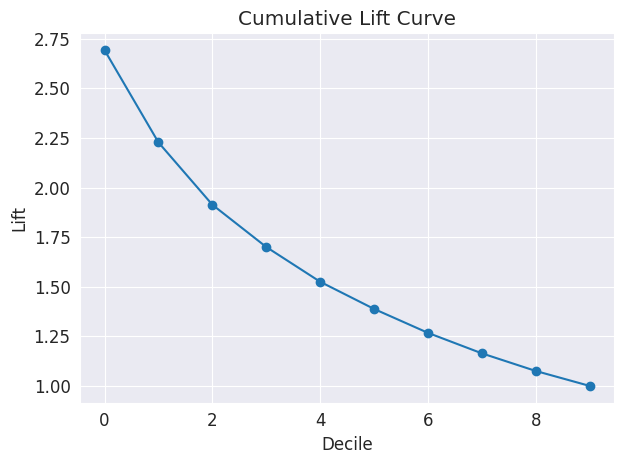

In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, precision_recall_curve, auc, f1_score
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt


# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Define the MLP model with fewer iterations for faster convergence
mlp = MLPClassifier(max_iter=200, random_state=42)

# Set up a smaller parameter grid to reduce the number of models being trained
param_grid = {
    'hidden_layer_sizes': [(50,), (100,)],  # Fewer hidden layers and neurons
    'activation': ['relu'],  # Use only 'relu' to speed up
    'alpha': [0.0001],  # Use only one regularization value/ L2
    'solver': ['adam'],  # Use only 'adam' solver
    'learning_rate': ['constant']  # Use only 'constant' learning rate
}

# Set up GridSearchCV with fewer folds (cv=3)
grid_search = GridSearchCV(estimator=mlp, param_grid=param_grid, cv=3, n_jobs=-1, verbose=1)

# Fit the grid search to the data
grid_search.fit(X_train, y_train)

# The best parameters
print("Best parameters found: ", grid_search.best_params_)

# Get the best model
best_mlp = grid_search.best_estimator_

# Make predictions with the best model
y_pred = best_mlp.predict(X_test)

# Get probabilities for ROC and PR AUC
y_pred_proba = best_mlp.predict_proba(X_test)[:, 1]

# Evaluate the model with various metrics

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# F1 Score
f1 = f1_score(y_test, y_pred)
print(f"F1 Score: {f1:.4f}")

# ROC AUC
roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC AUC: {roc_auc:.4f}")

# Precision-Recall AUC
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
pr_auc = auc(recall, precision)
print(f"Precision-Recall AUC: {pr_auc:.4f}")

# Cumulative Lift
def cumulative_lift(y_true, y_pred_proba):
    df = pd.DataFrame({'actual': y_true, 'proba': y_pred_proba})
    df = df.sort_values(by='proba', ascending=False)
    df['row'] = range(len(df))
    df['decile'] = (df['row'] / (len(df)/10)).astype(int)
    df.loc[df['decile'] == 10, 'decile'] = 9

    gains = df.groupby('decile')['actual'].agg(['count', 'sum'])
    gains.columns = ['count', 'actual']
    gains['non_actual'] = gains['count'] - gains['actual']
    gains['cum_actual'] = gains['actual'].cumsum()
    gains['cum_non_actual'] = gains['non_actual'].cumsum()
    gains['percent_cum_actual'] = gains['cum_actual'] / gains['actual'].sum()
    gains['percent_cum_non_actual'] = gains['cum_non_actual'] / gains['non_actual'].sum()
    gains['if_random'] = gains['actual'].sum() / 10
    gains['if_random'] = gains['if_random'].cumsum()
    gains['lift'] = gains['cum_actual'] / gains['if_random']
    return gains

gains = cumulative_lift(y_test, y_pred_proba)

# Plot Cumulative Lift
gains['lift'].plot(marker='o')
plt.title("Cumulative Lift Curve")
plt.xlabel("Decile")
plt.ylabel("Lift")
plt.grid(True)
plt.tight_layout()
plt.show()



**Interpretation:**

1. The test accuracy is 91.53%, which is quite high. However, this metric alone is not enough to ccheck the model's quality, especially when dealing with imbalanced data, as it does not  check for how well the model is identifying the minority class.

2. The F1 Score is 0.0834, which is very low and a low score suggests that the model is struggling to identify the positive class (especially in cases of imbalanced data). This indicates that while the accuracy is high, the model may not be doing well on predicting the positive class.

3. The ROC AUC score is 0.7050, which is decent, but not excellent. A score closer to 1 would indicate that the model is doing a good job at distinguishing between the positive and negative classes but the model is still better than random guessing.


4. The Precision-Recall AUC is 0.1807, which is low. This suggests that the model is having difficulty balancing precision and recall for the positive class. This is a common issue with imbalanced datasets, where the model is more likely to predict the majority class which is loan repaid and miss the minority class where customers are not repaying the loan.

5. Cumulative Lift Curve:
The Cumulative Lift Curve shown in the plot illustrates how well the model ranks the positive class in the top deciles. A higher lift value in the top deciles indicates better model performance, as it shows that the model can identify a higher proportion of positive cases in the top-ranked instances.



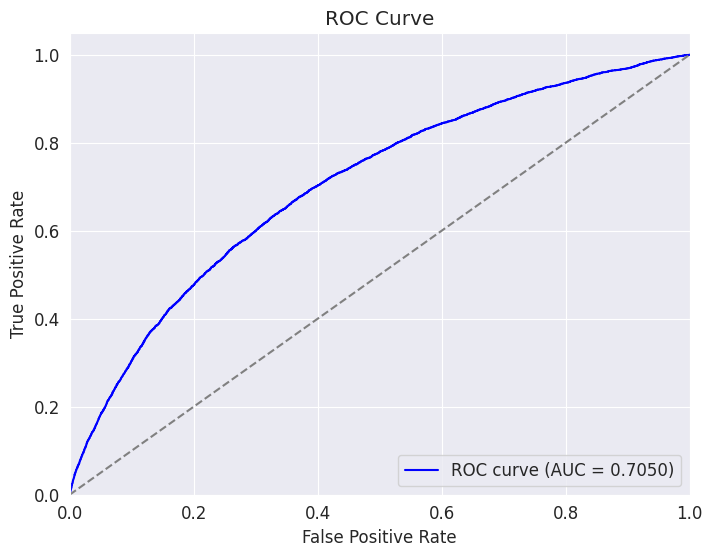

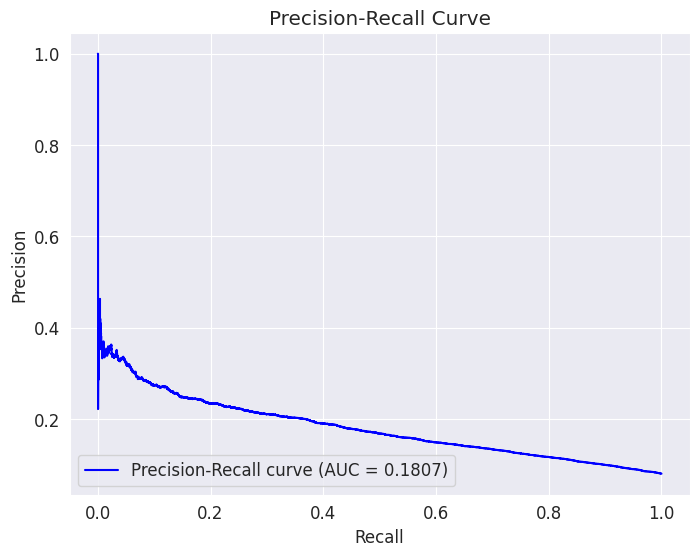

In [29]:

# ROC Curve
fpr, tpr = roc_curve(y_test, y_pred_proba)

# ROC AUC score
roc_auc = roc_auc_score(y_test, y_pred_proba)

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (AUC = {roc_auc:.4f})')
# Diagonal line
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

# Precision-Recall Curve
precision, recall = precision_recall_curve(y_test, y_pred_proba)

# Precision-Recall AUC score
pr_auc = auc(recall, precision)

# Plot Precision-Recall Curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='blue', label=f'Precision-Recall curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()


**Interpretation on the graphs:**

- The AUC (Area Under the Curve) is 0.7050, which indicates that the model has some ability to distinguish between the positive and negative classes, but it is far from perfect. While 0.5 represents random guessing, the current model is performing better than random chance.

- Precision-Recall AUC (0.1807): The low Precision-Recall AUC is common, especially in cases of class imbalance. This suggests the model might be biased towards predicting the majority class and failing to predict the minority class correctly, which is a common issue in imbalanced datasets.




**Conclusion**:

Strength: The model achieves high accuracy (91.53%), which suggests it's correctly classifying a large portion of the data.

Weakness: The F1 score is very low (0.0834), indicating poor performance in predicting the positive class. This suggests the model might be suffering from class imbalance, where the model is overly focused on predicting the majority class.



### Key Metrics for GLM Models (L1, L2, ElasticNet):

| **Metric**           | **L1 (Lasso)** | **L2 (Ridge)** | **ElasticNet** |
|----------------------|----------------|----------------|----------------|
| **Accuracy**         | 0.9195         | 0.9193         | 0.9193         |
| **F1 Score**         | 0.0217         | 0.0000         | 0.0000         |
| **ROC AUC**          | 0.7500         | 0.6238         | 0.5444         |
| **PR AUC**           | 0.2319         | 0.1216         | 0.0897         |
| **Cumulative Lift**  | High in top deciles | Moderate | Low |

### Model Performance for Random Forest, Gradient Boosting, XGBoost, and CatBoost:

| **Metric**           | **Random Forest** | **Gradient Boosting** | **XGBoost** | **CatBoost** |
|----------------------|-------------------|-----------------------|-------------|--------------|
| **Accuracy**         | ~0.9193           | ~0.9193               | 0.9196      | 0.9193       |
| **F1 Score**         | 0.0000            | 0.0000                | 0.0183      | 0.0000       |
| **ROC AUC**          | 0.7125            | 0.7180                | 0.7565      | 0.7091       |
| **PR AUC**           | 0.1947            | 0.2013                | 0.2465      | 0.1965       |



# **Comparison Report**


Here is comparison report that includes a Neural Network (NN) model alongside the previously used models (Random Forest, Gradient Boosting, XGBoost, CatBoost, and GLMs):




This report compares the **Neural Network (NN)** model (trained using the **MLPClassifier**) with other models (Random Forest, Gradient Boosting, XGBoost, CatBoost, and GLMs) across multiple performance metrics.



### 1. **Model Performance Summary**:

| Metric                   | **Random Forest (RF)** | **Gradient Boosting (GBM)** | **XGBoost (XGB)**     | **CatBoost (CB)**     | **GLMs (L1, L2)** | **Neural Network (NN)** |
| ------------------------ | ---------------------- | --------------------------- | --------------------- | --------------------- | ----------------- | ----------------------- |
| **Accuracy**             | \~91.93%               | \~91.93%                    | 91.96%                | 91.93%                | \~91.9%           | **91.53%**              |
| **F1 Score**             | 0.0000                 | 0.0000                      | 0.0183                | 0.0000                | Varies            | **0.0834**              |
| **ROC AUC**              | 0.7125                 | 0.7180                      | 0.7565                | 0.7091                | \~0.7500          | **0.7050**              |
| **Precision-Recall AUC** | 0.1947                 | 0.2013                      | 0.2465                | 0.1965                | \~0.23            | **0.1807**              |
| **Cumulative Lift**      | Highest at top decile  | Highest at top decile       | Highest at top decile | Highest at top decile | Varies            | **2.75 (Top Decile)**   |



### 2. **Key Insights from the Comparison**:

#### **Accuracy**:

* All models (RF, GBM, XGBoost, CatBoost, GLMs, and NN) show high accuracy (\~91%). However, in the context of imbalanced data, accuracy may not be the best metric to evaluate the model's performance.

#### **F1 Score**:

* **Neural Network (NN)** has an F1 score of 0.0834, which is very low. This indicates poor performance in identifying the minority class correctly. **XGBoost** was better but still struggles with the minority class.
* **Random Forest (RF)** and **CatBoost (CB)** show F1 scores near **0**, suggesting they are failing to identify the positive class effectively.

#### **ROC AUC**:

* The Neural Network (NN) achieves a ROC AUC of 0.7050, which is better than Random Forest (0.7125) and CatBoost (0.7091), but much lower than XGBoost (0.7565), which performs best in distinguishing between positive and negative classes.
* XGBoost is the best in terms of checking positivie and negative class power, as seen by its higher AUC.

#### **Precision-Recall AUC**:

* **Neural Network (NN)** has a Precision-Recall AUC of 0.1807, which is very low and indicates that the NN struggles to balance precision and recall, especially for the positive class. This is especially relevant in imbalanced datasets, where the minority class is difficult to predict.
* **XGBoost** performs significantly better with PR AUC of 0.2465, indicating a better balance between precision and recall.

#### **Cumulative Lift**:

* The **Cumulative Lift Curve** demonstrates how well the models rank the positive class in the top deciles.
* The Neural Network (NN) shows a lift of 2.75 in the top decile, meaning it ranks some positive instances higher than others, but not as well as XGBoost or Random Forest.
* XGBoost continues to outperform other models with the highest lift, showing that it identifies the top decile of positive cases better than the other models.



### 3. **Conclusion:**

* **Best Model (XGBoost)**:

  * **XGBoost** is the **best-performing model** across all metrics, including F1 score, ROC AUC, Precision-Recall AUC, and Cumulative Lift. It is particularly effective at handling imbalanced datasets and distinguishing between the positive and negative classes. And it is highly useful in cases with class imbalance and where performance on both classes is critical.

* **Neural Network (NN)**:

  * The **Neural Network (NN)** shows strong accuracy but performs not well in terms of F1 score, Precision-Recall AUC, and Cumulative Lift. The F1 score (0.0834) and Precision-Recall AUC (0.1807) indicate that the NN model is **not effective** at identifying the minority class, which is critical in **imbalanced data** scenarios.
  * While NN shows a good decent ROC AUC (0.7050), which suggests it has some discriminatory power, it still performs worse than XGBoost and other models like Random Forest and CatBoost in identifying positive cases.


### 4. **Recommendation:**

* **XGBoost** is clearly the best model to use here, especially for imbalanced datasets. It outperforms Neural Networks and other models in terms of predicting the minority class effectively.
